Paquetes necesarios

In [2]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv
from scipy.optimize import least_squares

### Resolución de la Tarea 1: Detección de monedas en tiempo real

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



In [2]:

cobre={16.25: 0.01, 18.75:0.02, 21.25: 0.05}
oro={19.75:0.1, 22.25: 0.2, 24.25:0.5}
plata = {23.25:1, 25.75:2}

ESC = 7                      # px por mm
CROMA_MINIMO  = 12     # por debajo, la moneda no es cobre ni oro: medida dudosa
H_CORTE       = 70     # grados: < cobre, > oro
vid = cv2.VideoCapture(0)


# Función que obtiene centro y radio óptimos por mínimos cuadrados
def minimosCuadrados(p):
    p = np.asarray(p, dtype=float)
    # Estimación inicial del centro
    initial_center = np.mean(p, axis=0)

    # Estimación inicial del radio
    min_distances = np.linalg.norm(
        p - initial_center, axis=1
    )
    initial_radio = np.mean(min_distances)

    # Error geométrico: distancia al centro menos radio
    def err(param):
        xc, yc, radio = param
        distances = np.sqrt(
            (p[:, 0] - xc)**2
            + (p[:, 1] - yc)**2
        )
        return distances - radio

    result = least_squares(
        err,
        x0=[*initial_center, initial_radio],
        bounds=(
            [-np.inf, -np.inf, 0],
            [np.inf, np.inf, np.inf]
        )
    )

    x, y, radio = result.x
    return (x,y), radio



def measure_coin(x, y, r, M, ESC, n=36):
    approximation = []
    for grad in range(0,360,2):
        approximation.append([x+r*np.cos(np.deg2rad(grad)), y+r*np.sin(np.deg2rad(grad))])
    approximation = np.array(approximation, dtype=np.float32)
    approximation = approximation.reshape(-1, 1, 2)
    p = cv2.perspectiveTransform(approximation, M).reshape(-1,2)   # a coords del plano (px de out)

    # ajuste de círculo por mínimos cuadrados
    center_opt ,r_opt = minimosCuadrados(p)
    return center_opt, 2 * r_opt / ESC       # centro en out, diámetro en mm



def sort_points(pts):
    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).ravel()
    return np.array([pts[s.argmin()],   # arriba-izq
                     pts[d.argmin()],   # arriba-der
                     pts[s.argmax()],   # abajo-der
                     pts[d.argmax()]],  # abajo-izq
                    dtype=np.float32)

# Función que detecta las esquinas del folio
def find_whitepaper(frame, blur):
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None

    c = max(cnts, key=cv2.contourArea)
    if cv2.contourArea(c) < 0.1 * frame.shape[0] * frame.shape[1]:
        return None

    # Perímetro y array de puntos de las esquinas del folio
    peri = cv2.arcLength(c, True)                       
    quad = cv2.approxPolyDP(c, 0.02 * peri, True)
    if len(quad) != 4:
        return None
    return sort_points(quad.reshape(4, 2).astype(np.float32))


# Función que obtiene la mediana de color del frame transformado, es decir del folio.
def ganancia_blanco(out, step=8):
    return np.median(out[::step, ::step].reshape(-1, 3), axis=0).astype(np.float32)

#Función para obtener el color de la moneda
def color_moneda(frame, x, y, r, ganancia):
    x, y, r = int(x), int(y), int(r)

    roi = frame[y:y + r, x:x + r]
    if roi.shape[0] < r or roi.shape[1] < r:
        return None

    #Normaliza el color del roi en base a la ganancia de blanco del folio
    #Devolviendo el array con los valores BGR normalizados
    norm = np.clip(roi.astype(np.float32) / ganancia * 0.85, 0, 1)
    lab = cv2.cvtColor(norm, cv2.COLOR_BGR2LAB)

    #Se generan matrices de coordenadas verticales y horizontales respectivamente
    yy, xx = np.indices(roi.shape[:2])
    dist = np.hypot(xx, yy)
    valido = (lab[..., 0] > 20) & (lab[..., 0] < 90)


    #Creación de máscaras para el anillo y centro y mediana de estas máscaras
    c = lab[(dist < 0.40 * r) & valido]
    a = lab[(dist > 0.82 * r) & (dist < 0.95 * r) & valido]
    c, a = np.median(c, axis=0), np.median(a, axis=0)

    #Calculo del croma en el centro y en la anilla para determinar la vivacidad de ambas máscaras
    Cc = np.hypot(c[1], c[2]) + 1.0 
    Ca = np.hypot(a[1], a[2]) + 1.0
    s = np.log(Cc / Ca)

    #Si el centro tiene mayor croma que el anillo, entonces en bimetal
    if abs(s) > 0.45:
        return "bimetal"
    if Ca < CROMA_MINIMO:
        return None
    #Calcula el angulo de corte entre a1 y a2. Cuanto mayor sea, más se acerca a oro
    return "cobre" if np.degrees(np.arctan2(a[2], a[1])) < H_CORTE else "oro"


#Clase que representa una moneda trackeada, con su historial de diams, valor, color y frames analizados
from collections import deque
class Track:
    def __init__(self, cx, cy, n=25):
        self.cx, self.cy = cx, cy
        self.diams = deque(maxlen=n)      # últimos n diámetros
        self.colores = deque(maxlen=n)    # últimas n etiquetas de color
        self.value = deque(maxlen=n)      # últimos n valores
        self.visto = 0

tracks = []

# Función que añade una moneda o "track" si esta no está "trackeada"
def asociar(cx, cy, dist_max=10):
    for t in tracks:
        if np.hypot(t.cx - cx, t.cy - cy) < dist_max:
            t.cx, t.cy = 0.9*t.cx + 0.1*cx, 0.9*t.cy + 0.1*cy
            return t

    #Si no hay monedas similares, se añade
    t = Track(cx, cy)
    tracks.append(t)
    return t

# Función para obtener el valor más proximo dado un diametro y su color/tabla de color
def clasify_coin(diam, tabla):
    mejor = min(tabla, key=lambda k: abs(k - diam))
    if abs(mejor - diam) <= mejor * 0.10:
        return tabla[mejor]
    return None



In [9]:

vid = cv2.VideoCapture(0)
vid.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
vid.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
vid.set(cv2.CAP_PROP_AUTOFOCUS, 0)
vid.set(cv2.CAP_PROP_AUTO_WB, 0)

cv2.namedWindow("plano folio", cv2.WINDOW_NORMAL)
cv2.resizeWindow("plano folio", 800, 600)
frame_idx = 0
while True:
    ret, view = vid.read()
    view_copy = view.copy()
    if ret:
        total_value = 0.0
        num_coins = 0
        frame_idx += 1
        gris = cv2.cvtColor(view_copy, cv2.COLOR_BGR2GRAY)
        blur = cv2.GaussianBlur(gris, (7, 7), 0)

        #Detecta las esquinas del folio
        corners = find_whitepaper(view_copy, blur)

        if corners is not None:

            circ = cv2.HoughCircles(blur, cv2.HOUGH_GRADIENT, dp=1.2, minDist=10, param1=90, param2=40, minRadius=20, maxRadius=80)
            cv2.polylines(view_copy, [corners.astype(np.int32)], True, (0, 255, 0), 2)

            # orientación: ¿el lado superior es el largo o el corto?
            h_side = np.linalg.norm(corners[1] - corners[0])
            v_side = np.linalg.norm(corners[3] - corners[0])
            if h_side >= v_side:
                W, H = int(297 * ESC), int(210 * ESC)
            else:
                W, H = int(210 * ESC), int(297 * ESC)

            # Crea un nuevo frame que contenga solo el folio y realiza un cambio de perspectiva
            dst = np.float32([[0, 0], [W - 1, 0], [W - 1, H - 1], [0, H - 1]])
            M = cv2.getPerspectiveTransform(corners, dst)

            #Frame con el cambio de perspectiva, solo tiene el folio
            out = cv2.warpPerspective(view_copy, M, (W, H), flags=cv2.INTER_LINEAR)

            #Ganancia de blanco en el folio
            ganancia = ganancia_blanco(out)
            if circ is not None and M is not None:
                for x, y, r in circ[0]:
                    fixed_center, fixed_diam = measure_coin(x, y, r, M, ESC)

                    #Si hay diametros fuera de limites, pasamos
                    if fixed_diam > 26.15 or fixed_diam < 15.75:
                        continue

                    color = color_moneda(view, x, y, r, ganancia)

                    #Se obtiene un valor para el frame actual en base al color y diametro
                    if color=="cobre":
                        value = clasify_coin(fixed_diam, cobre)
                        num_coins += 1
                    elif color=="oro":
                        value = clasify_coin(fixed_diam, oro)
                        num_coins += 1
                    elif "bimetal"== color:
                        value = clasify_coin(fixed_diam, plata)
                        num_coins += 1
                    else:
                        value = None

                    #Se trackea la moneda si no lo estuviera y añade características
                    t = asociar(fixed_center[0] / ESC, fixed_center[1] / ESC)   # en mm
                    t.diams.append(fixed_diam)
                    if color is not None:
                        t.colores.append(color)
                    t.visto = frame_idx
                    if value is not None:
                        t.value.append(value)
                    cv2.circle(view_copy, (int(x), int(y)), int(r), (0, 255, 0), 2)

                    #Cuando se tiene suficientes frames de historial
                    if len(t.diams) >= 10:
                        if len(t.colores)==0 or len(t.value)==0 or len(t.diams)==0:
                            break

                        #Obtención de valores estimados
                        diam_est = np.median(t.diams)
                        color_est = max(set(t.colores), key=t.colores.count)
                        value_est = max(set(t.value), key=t.value.count)
                        
                        if color=="cobre":
                            t.value.append(clasify_coin(diam_est, cobre))
        
                        elif color=="oro":
                            t.value.append(clasify_coin(diam_est, oro))

                        elif "bimetal"==color:
                            t.value.append(clasify_coin(diam_est, plata))

                        else:
                            value = None

                        #Se muestra el diámetro y si hay valor estimado, el valor
                        cv2.putText(view_copy, f"{diam_est:.2f}", (int(x - 60), int(y)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

                        if value_est is not None:
                            total_value += value_est
                            cv2.putText(view_copy, f"{value_est:.2f}", (int(x + 5), int(y + 30)),cv2.FONT_HERSHEY_SIMPLEX, 1.3, (0, 0, 255), 2)

                cv2.putText(view_copy, f"Hay {num_coins} monedas, con un valor total de {total_value:.2f} euros", (20, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (160, 32, 240), 2)

            cv2.imshow("plano folio", out)
        #Se eliminan las monedas cada 30 frames
        tracks = [t for t in tracks if frame_idx - t.visto <= 30]
        cv2.imshow("camara", view_copy)
        if cv2.waitKey(20) == 27:
            break
              
vid.release()
cv2.destroyAllWindows()

La segunda tarea plantea la clasificación de microplásticos en una imagen real. Dado que el mundo real es muy variado, las imágenes no siempre se capturan con unas condiciones de iluminación tan buenas o controladas. Ejemplo con aplicación de variantes de umbralizados ofrecidas por OpenCV sobre una imagen de muestras de microplásticos.

Umbral escogido  197.0


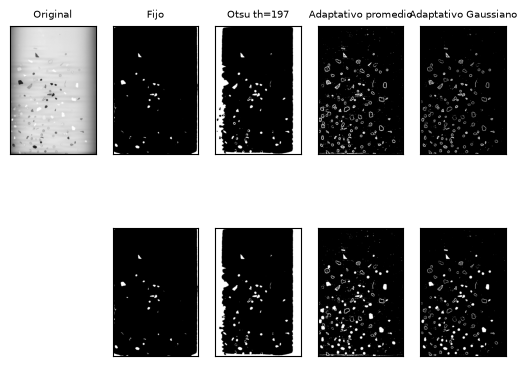

In [2]:
#Carga imagen directamente en grises
imgorig = cv2.imread('MPs_test.jpg', cv2.IMREAD_GRAYSCALE) 

img = cv2.GaussianBlur(imgorig,(5,5),0)

#Umbralizados
ret,imth1 = cv2.threshold(img,150,255,cv2.THRESH_BINARY_INV)
thotsu,imth2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral escogido ', thotsu)
imth3 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_MEAN_C,\
            cv2.THRESH_BINARY,11,2)
imth4 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,11,2)
 
titles = ['Original', 'Fijo','Otsu th='+str(int(thotsu)),
            'Adaptativo promedio', 'Adaptativo Gaussiano']
images = [img, imth1, imth2, 255 - imth3, 255 - imth4]
 
for i in range(5):
    plt.subplot(2,5,i+1),plt.imshow(images[i],'gray')
    plt.title(titles[i], fontsize=7)
    plt.xticks([]),plt.yticks([])

    #Obtiene únicamente los contornos externos
    if i>0:
        res,imth = cv2.threshold(images[i],120,255,cv2.THRESH_BINARY)
        contornos, hierarchy= cv2.findContours(imth, 
        cv2.RETR_EXTERNAL , 
        cv2.CHAIN_APPROX_SIMPLE)  
        img_cont = np.zeros(img.shape)
        cv2.drawContours(img_cont, contornos, -1, (255,255,255), -1)  
        plt.subplot(2,5,i+6),plt.imshow(img_cont,'gray')
        plt.xticks([]),plt.yticks([])
plt.show()

Para esta imagen de muestras de microplásticos tenemos una anotación (que puede contener errores) de la tipología de las partículas. Esta será la imagen de test en los experimentos posteriores, no puedes hacer uso de esta imagen para entrenar tu clasificador, solo par evaluarlo

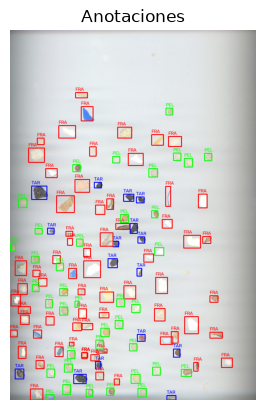

In [3]:
# Imagen y anotaciones
imagen = "MPs_test.jpg"          # Imagen original
csv_file = "MPs_test_bbs.csv"  # CSV con coordenadas y tipología

# Colores de cada clase
colores = {
    "FRA": (0, 0, 255),   # Rojo 
    "PEL": (0, 255, 0),   # Verde
    "TAR": (255, 0, 0)    # Azul
}

# Imagen
img = cv2.imread(imagen)

# Cara csv y dibujar rectángulos
with open(csv_file, newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        etiqueta = row["label"]
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])
        
        # Color según etiqueta
        color = colores.get(etiqueta, (0, 0, 0))  # negro por defecto si no encuentra
        
        # Dibujar rectángulo
        cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)
        
        # Etiqueta 
        cv2.putText(img, etiqueta, (x_min, y_min - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

# Visualiza resultado
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Anotaciones")
plt.axis('off')
plt.show()


##Muestras de entrenamiento

Text(0.5, 1.0, 'Alquitrán')

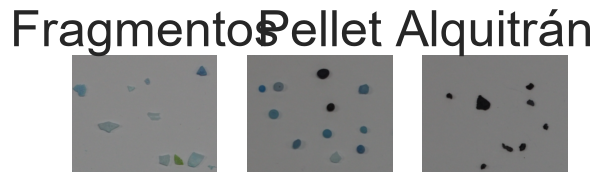

In [9]:
#Cargamos tres subimágenes, por simplicidad, de cada uno de los tres tipos considerados (reiterar que el alquitrán no es microplástico)
imgF = cv2.imread('./tarea2_img/fragment/FRA.png') 
imgP = cv2.imread('./tarea2_img/pellet/PEL.png') 
imgT = cv2.imread('./tarea2_img/alquitran/TAR.png') 

#Mostramos
plt.subplot(131)
plt.axis("off")
plt.imshow(imgF) 
plt.title('Fragmentos')
plt.subplot(132)
plt.axis("off")
plt.imshow(imgP) 
plt.title('Pellet')
plt.subplot(133)
plt.axis("off")
plt.imshow(imgT) 
plt.title('Alquitrán')

El objetivo de la siguiente tarea, descrita más abajo, es desarrollar tu propio clasificador basado únicamente en heurísticas basadas en características geométricas y/o de apariencia, a partir de las imágenes completas de las partículas de cada tipo, debiendo mostrar la bondad del clasificador haciendo uso de métricas para ello sobre las anotaciones de la imagen de test *MPs_test.png*. La siguiente celda obtiene varias métricas para un conjunto de datos imaginario (y con etiquetas aleatorias). Si bien las trataremos con más detalle en teoría, muestro un repertorio de ellas, dando más peso a la matriz de confusión. La ejecución de la celda requiere instalar el paquete scikit-learn.

¿Qué es una matriz de confusión?
Se utiliza para mostrar el comportamiento de un clasificador para las distintas clases conocidas, se relacionan las etiquetas de las muestras anotadas frente a las predichas por el clasificador. Se busca una matriz diagonal, pero la perfección es infrecuente.

El siguiente ejemplo, muestra el modo de obtener la matriz de confusión para un hipotético problema con cuatro clases, y valores de anotación (variable y) y predicción (variable y_pred) obtenidos de forma aleatoria.

Anotaciones  [3, 2, 1, 0, 1, 1, 0, 1, 3, 2, 2, 2, 0, 2, 3, 1, 2, 1, 2, 3, 2, 1, 1, 3, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 3, 1, 2, 3, 2, 0, 2, 3, 1, 1, 1, 3, 0, 0, 3, 1, 1, 3, 1, 0, 2, 2, 2, 3, 2, 2, 3, 0, 0, 2, 1, 3, 3, 2, 2, 2, 2, 2, 1, 0, 3, 0, 3, 3, 3, 3, 3, 0, 0, 1, 1, 3, 2, 1, 0, 0, 2, 2, 3, 2, 2, 2, 1, 1, 3, 2]
Predicciones  [2, 3, 2, 0, 0, 0, 3, 1, 3, 3, 3, 3, 3, 2, 2, 3, 1, 2, 0, 2, 2, 1, 0, 0, 1, 0, 3, 0, 1, 0, 3, 0, 0, 0, 1, 0, 2, 3, 0, 0, 1, 0, 2, 2, 2, 3, 1, 3, 1, 2, 2, 0, 3, 2, 3, 2, 3, 1, 0, 1, 2, 0, 3, 1, 1, 0, 3, 3, 3, 0, 3, 3, 0, 3, 2, 3, 3, 3, 1, 2, 2, 2, 3, 1, 2, 2, 3, 3, 2, 1, 1, 3, 1, 0, 3, 0, 0, 1, 2, 0]
¿Cómo de bien encajan anotación y predicción?
Accuracy (TP/(n))= 0.21
Precision (TP/(TP+FP)) = 0.21166753732967653
Recall (TP/(TP+FN)) = 0.21
F1 Score (2*(precision*recall)/(precision+recall)) = 0.20753202032367027


Text(38.236490885416664, 0.5, 'Real/Anotado')

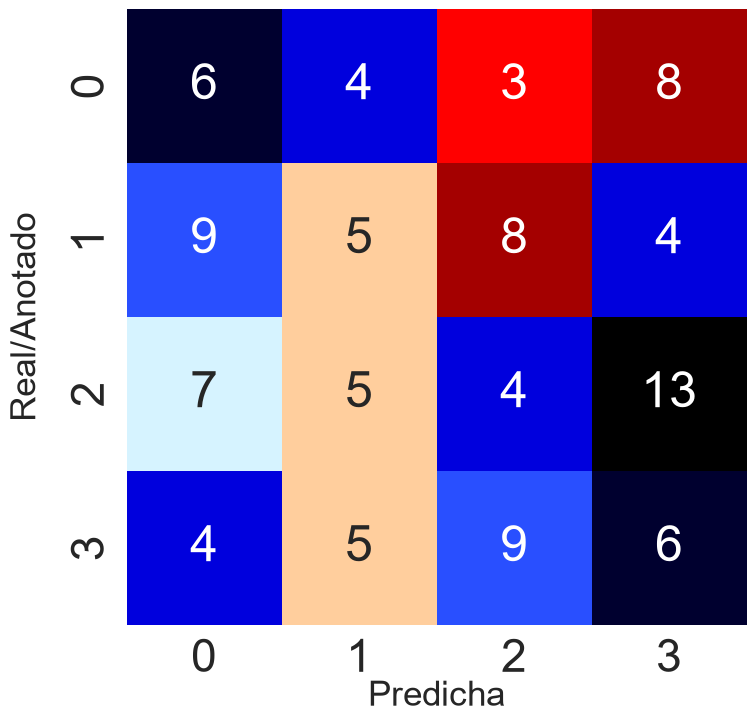

In [7]:

import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Numero de muestras
n = 100  
nclases = 4

# A falta de clasificador y conjunto de datos, creamos anotaciones y predicciones de forma aleatoria
# Vector aleatorio con etiquetas anotadas
y = [random.randint(0, nclases - 1) for _ in range(n)]
print('Anotaciones ' , y)

# Vector aleatorio con etiquetas predichas por un supuesto clasificador
y_pred = [random.randint(0, nclases - 1) for _ in range(n)]
print('Predicciones ' , y_pred)

print('¿Cómo de bien encajan anotación y predicción?')

#Cálculo de métricas
accuracy = accuracy_score(y, y_pred)
#Para más de una clase se define la forma de promediar
precision = precision_score(y, y_pred,average='weighted')
recall = recall_score(y, y_pred,average='weighted')
f1score = f1_score(y, y_pred,average='weighted')

print(f"Accuracy (TP/(n))= {accuracy}")
print(f"Precision (TP/(TP+FP)) = {precision}")
print(f"Recall (TP/(TP+FN)) = {recall}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")


conf_matrix = confusion_matrix(y, y_pred)
plt.figure(figsize=(8,8))
sns.set(font_scale = 1.75)#tamaños tipografía
sns.set(font_scale = 3.0)

ax = sns.heatmap(
        conf_matrix, # confusion matrix 2D array 
        annot=True, # Muestra números en las celdas
        fmt='d', # valores enteros
        cbar=False, # sin barra de colores
        cmap='flag', # mapa de colores
        #vmax=175 # contraste de color
    )

#Etiquetas matriz de confusión
label_font = {'size':'25'}
ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

## Solución tarea 2

Para la detección y clasificación de partículas de distintos tipos, usaremos diferentes heurísticas basadas en propiedades físicas que se ven a simple vista en las particulas a clasificar en las imagenes de entrenamiento, en primer lugar, debemos definir funciones auxiliares que nos permitan detectar partículas en las imagenes y extraer diferentes características geométricas de las mismas, además de visualizar segmentaciones y contornos

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FEATURE_NAMES = ["circularidad"]

# función para cargar una imagen
def cargar(ruta):
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"No existe: {os.path.abspath(ruta)}")
    img = cv2.imread(ruta)
    if img is None:
        raise ValueError(f"OpenCV no pudo leer: {ruta}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# funcion que dada una imagen, devuelve una máscara binaria con las
# particulas de la imagen en blanco sobre negro
def segmentar(img_rgb, area_min=50, area_max=None, block_size=81, C=5, kernel=5):
    
    gris = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)

    # máscara con umbral adaptativo 
    mask = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                                 cv2.THRESH_BINARY_INV, block_size, C)

    # Limpia ruido y pequeños huecos 
    if kernel > 1:
        ker = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (kernel, kernel)
        )
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, ker)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, ker)

    mask = rellenar_huecos(mask)

    # Eliminar y filtrar componentes conectados

    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)

    result = np.zeros_like(mask)

    for i in range(1, n):  # El componente 0 corresponde al fondo.
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= area_min and (area_max is None or area <= area_max):
            result[labels == i] = 255

    return result



def rellenar_huecos(mask):
    contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    result = np.zeros_like(mask)
    cv2.drawContours(result, contornos, -1, 255, thickness=cv2.FILLED)
    return result


# función que dado un contorno, calcula sus características
# devuelve su circularidad y una tupla con las coordenadas
# de la caja que envuelve a la partícula
def caracteristicas_contorno(cnt):
    area = cv2.contourArea(cnt)
    perimetro = cv2.arcLength(cnt, True)

    if area <= 0 or perimetro <= 0:
        return None

    circularidad = 4 * np.pi * area / (perimetro ** 2)
    caja = cv2.boundingRect(cnt)

    return circularidad, caja


def lab_por_particula(img_rgb, cnt, lab_img, erosion=3):
    m = np.zeros(img_rgb.shape[:2], np.uint8)
    cv2.drawContours(m, [cnt], -1, 255, cv2.FILLED)
    if erosion > 1:  # quita el borde, donde se mezcla con el fondo
        m = cv2.erode(m, np.ones((erosion, erosion), np.uint8))
    if cv2.countNonZero(m) == 0:  # partícula demasiado pequeña
        return [np.nan, np.nan, np.nan]
    L, a, b, _ = cv2.mean(lab_img, mask=m)
    return [L, a, b]


# función que de una máscara binaria devuelve un DataFrame con
# las características de cada partícula, una lista con los contornos
# de cada particula, y una lista con la caja delimitadora de cada partícula
def extraer_particulas(mask, img_rgb=None):
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    # Lab en float32: así L va de 0 a 100 y a/b ya vienen centrados en 0
    lab_img = None
    if img_rgb is not None:
        lab_img = cv2.cvtColor(img_rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB)

    filas, contornos, cajas, colores = [], [], [], []
    for c in cnts:
        r = caracteristicas_contorno(c)
        if r is None:
            continue
        caracteristicas, caja = r
        filas.append(caracteristicas)
        contornos.append(c)
        cajas.append(caja)
        if lab_img is not None:
            colores.append(lab_por_particula(img_rgb, c, lab_img))

    df = pd.DataFrame(filas, columns=FEATURE_NAMES)
    if lab_img is not None:
        df[["L", "a", "b"]] = np.array(colores)
    return df, contornos, cajas


# función para mostrar en una imagen las características de la misma
def mostrar_segmentacion(img_rgb, mask, cnts=None, bbs=None, titulo=""):
    vis = img_rgb.copy()
    if cnts is None:
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(vis, cnts, -1, (0, 255, 0), 2)
    if bbs is not None:
        for i, (x, y, w, h) in enumerate(bbs):
            cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
            cv2.putText(vis, str(i), (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX,
                        0.8, (255, 0, 0), 2)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(img_rgb); ax[0].set_title("Original")
    ax[1].imshow(mask, cmap="gray"); ax[1].set_title("Máscara")
    ax[2].imshow(vis); ax[2].set_title("Contornos" + (" " + titulo if titulo else ""))
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()

Una vez contamos con estas funciones podemos comenzar a usarlas para detectar y visualizar particulas en imágenes, extrayendo sus características

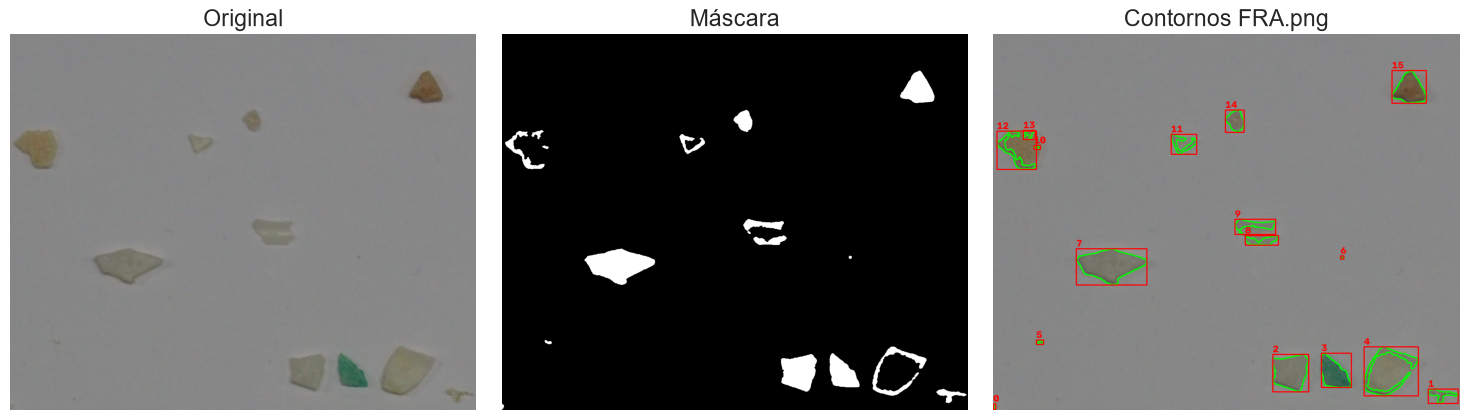

16 partículas


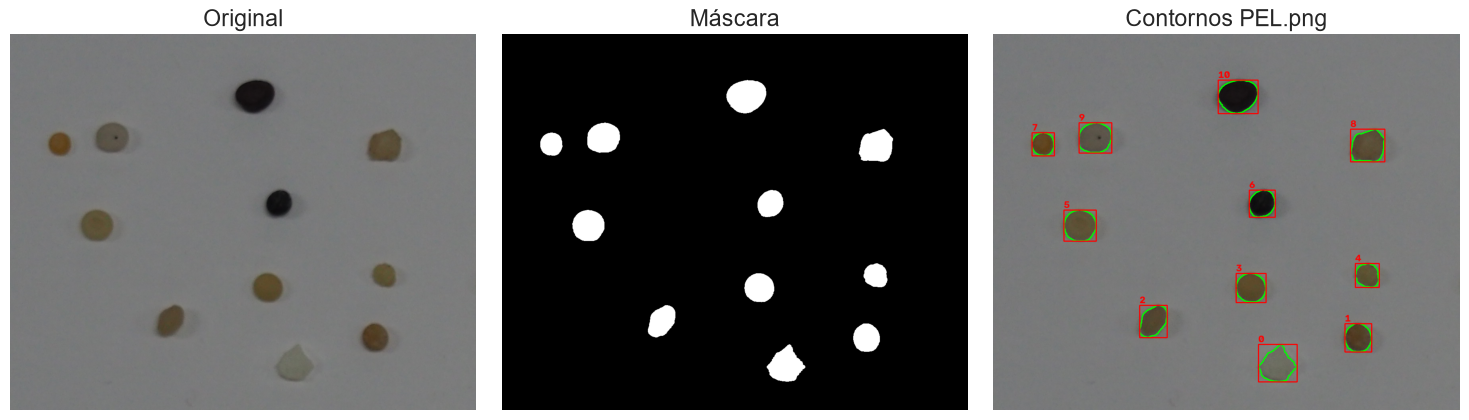

11 partículas


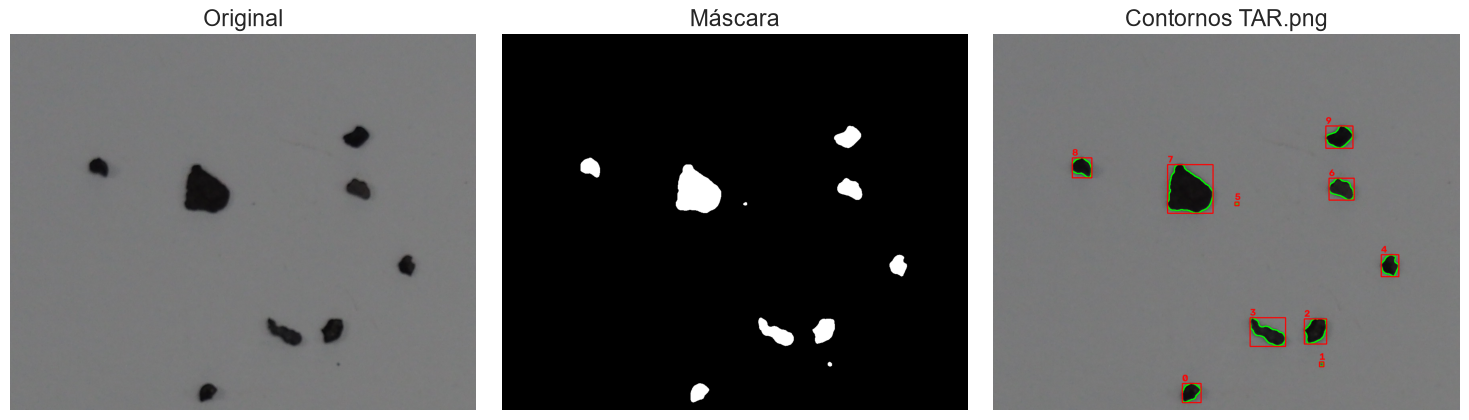

10 partículas


In [95]:
for ruta in ['./tarea2_img/fragment/FRA.png',
             './tarea2_img/pellet/PEL.png',
             './tarea2_img/alquitran/TAR.png']:
    img = cargar(ruta)
    mask = segmentar(img)
    df, cnts, bbs = extraer_particulas(mask)
    mostrar_segmentacion(img, mask, cnts, bbs, titulo=os.path.basename(ruta))
    print(len(df), "partículas")

Ahora a modo de heurística, vamos a establecer diferentes umbrales que en función de estos determinarán el tipo de una partícula detectada en la imagen, en concreto definiremos dos umbrales:

- **La circularidad de una partícula:** Esto es debido a que las partículas de Pellet son considerablemente redondas, con valores de circularidad cercanos al 100%, bastante al contrario que las partículas de Alquitrán y Fragment
- **Color LAB de una partícula**: Esto es debido a que las partículas de Alquitrán tienen a colores mucho más oscuros que las partículas de Pellet y Fragment, hemos decidido usar LAB sobre otras representaciones de color como RGB porque son más interesantes y precisas a la hora de medir qué tan oscuro es algo

El primer paso es obtener información sobre circularidad y color de las imágenes de ejemplo de cada clase, comenzaremos por la circularidad

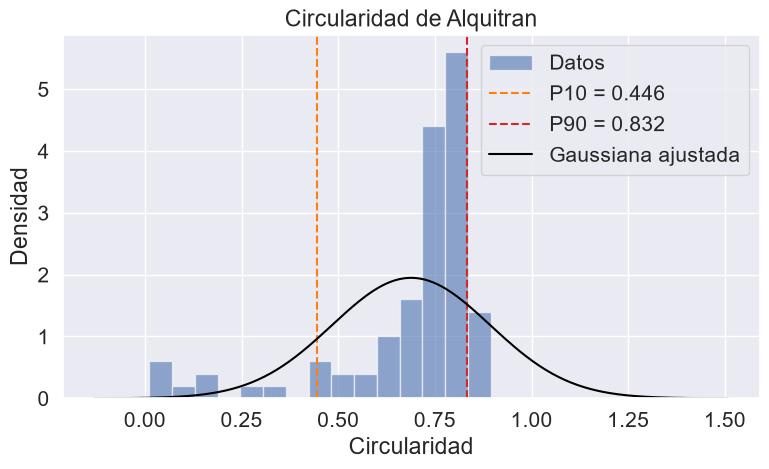

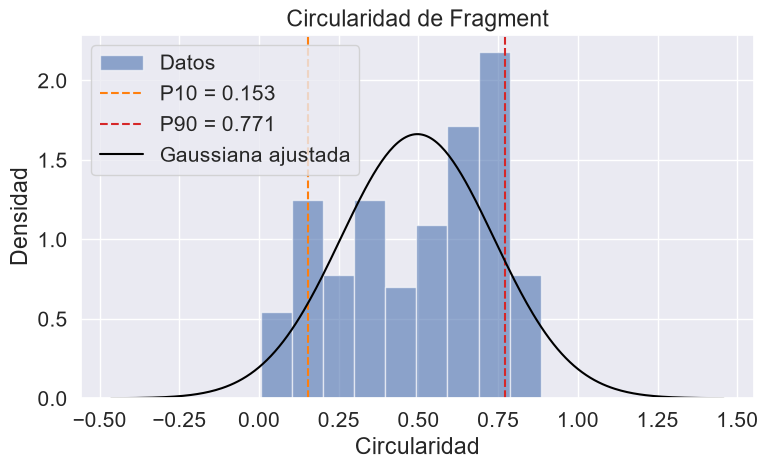

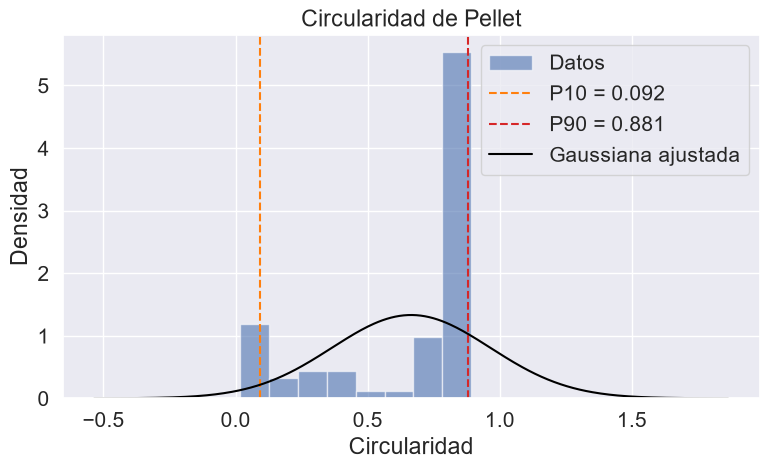

Variables Alquitan


,minimo,maximo,media,p10,p90
0,0.0114,0.894,0.6887,0.4456,0.832


Variables Fragment


,minimo,maximo,media,p10,p90
0,0.0069,0.8831,0.4966,0.1531,0.7708


Variables Pellet


,minimo,maximo,media,p10,p90
0,0.0151,0.8928,0.6644,0.0924,0.8805


In [96]:
def _dibujar_histograma_gauss(valores, nombre, ax):
    valores = np.asarray(valores, dtype=float)
    media = valores.mean()
    desviacion = valores.std()
    ax.hist(valores, bins="auto", density=True, alpha=0.6, label="Datos")
    p10, p90 = np.percentile(valores, [10, 90])
    ax.axvline(p10, color="tab:orange", linestyle="--", label=f"P10 = {p10:.3f}")
    ax.axvline(p90, color="tab:red", linestyle="--", label=f"P90 = {p90:.3f}")
    if desviacion > 0:
        x = np.linspace(min(valores.min(), media - 4 * desviacion),
                        max(valores.max(), media + 4 * desviacion), 300)
        gauss = np.exp(-0.5 * ((x - media) / desviacion) ** 2) / (desviacion * np.sqrt(2 * np.pi))
        ax.plot(x, gauss, color="black", label="Gaussiana ajustada")
    else:
        ax.text(0.5, 0.95, "Desviacion nula: no se puede ajustar una gaussiana",
                ha="center", va="top", transform=ax.transAxes, fontsize=8)
    ax.set_title(nombre)
    ax.set_ylabel("Densidad")
    ax.legend()


def calcular_umbrales_circularidad(img_rgb, leyenda):
    """Calcula circularidad por partícula, percentiles y distribución."""
    mask = segmentar(img_rgb)
    contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    registros = []
    for contorno in contornos:
        area = cv2.contourArea(contorno)
        perimetro = cv2.arcLength(contorno, True)
        if area > 0 and perimetro > 0:
            registros.append({
                "particula": len(registros) + 1,
                "circularidad": 4 * np.pi * area / (perimetro ** 2),
            })

    if not registros:
        raise ValueError("No se detectaron partículas con circularidad válida en la imagen.")

    df_circularidades = pd.DataFrame(registros)
    valores = df_circularidades["circularidad"]
    umbrales = {
        "minimo": float(valores.min()),
        "maximo": float(valores.max()),
        "media": float(valores.mean()),
        "p10": float(valores.quantile(0.10)),
        "p90": float(valores.quantile(0.90)),
    }
    fig, ax = plt.subplots(figsize=(8, 5))
    _dibujar_histograma_gauss(valores, leyenda, ax)
    ax.set_xlabel("Circularidad")
    fig.tight_layout()
    plt.show()
    return  umbrales

img_alquitran_entrenamiento = cargar("./tarea2_img/alquitran/tar-03-olympus-10-01-2020.JPG")
umbrales_circularidad_alquitran = calcular_umbrales_circularidad(img_alquitran_entrenamiento, "Circularidad de Alquitran")

img_fragment_entrenamiento = cargar("./tarea2_img/fragment/fragment-03-olympus-10-01-2020.JPG")
umbrales_circularidad_fragment = calcular_umbrales_circularidad(img_fragment_entrenamiento, "Circularidad de Fragment")

img_pellet_entrenamiento = cargar("./tarea2_img/pellet/pellet-03-olympus-10-01-2020.JPG")
umbrales_circularidad_pellet = calcular_umbrales_circularidad(img_pellet_entrenamiento, "Circularidad de Pellet")

print("Variables Alquitan")
display(pd.DataFrame([umbrales_circularidad_alquitran]).round(4))

print("Variables Fragment")
display(pd.DataFrame([umbrales_circularidad_fragment]).round(4))

print("Variables Pellet")
display(pd.DataFrame([umbrales_circularidad_pellet]).round(4))

Los datos nos revelan algo interesante, y es que la circularidad de las particulas de Fragment es considerablemente variada y en promedio no es muy elevada, por lo que no nos vale para clasificar particulas de este tipo usando la circularidad. Por otro lado, sí nos vale para diferenciarlas de Alquitran y Pellet, que de media valores bastante más elevados de circularidad.

Por lo que el nuevo objetivo consiste en encontrar una característica que nos ayude a diferenciar entre particulas de Alquitran y de Pellet, aquí es donde entra el color de la particula:

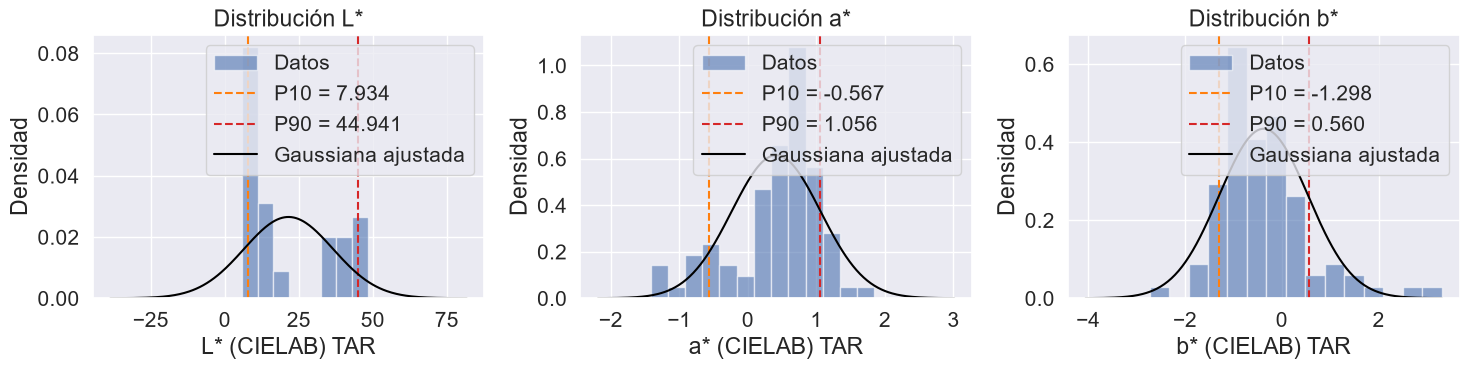

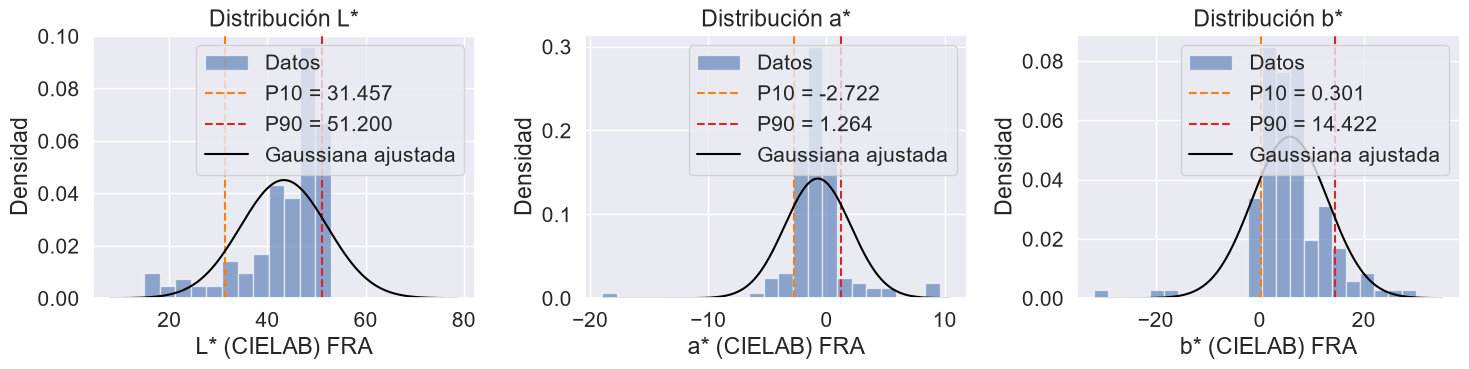

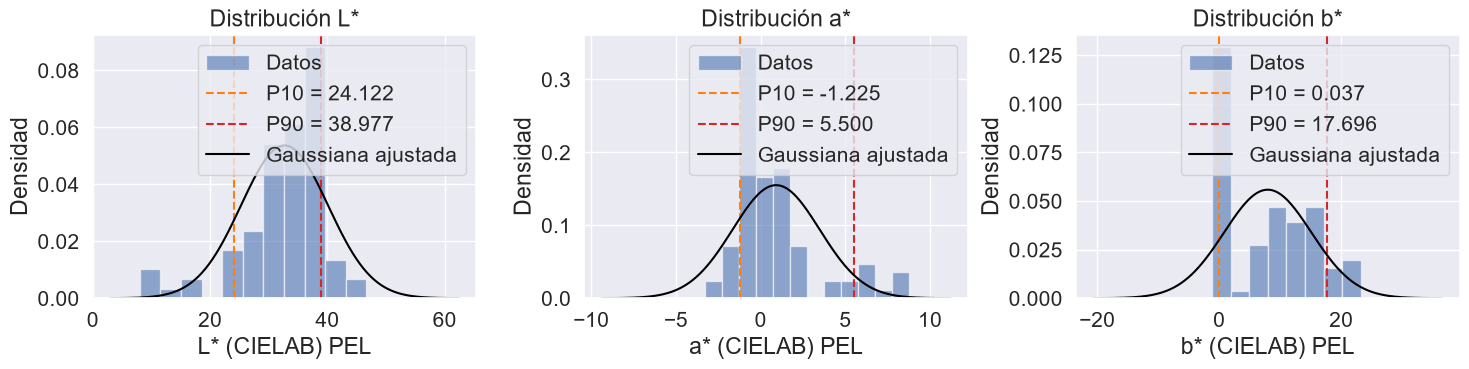

Umbrales de Alquitran


,L*,a*,b*
minimo,5.82,-1.42,-2.73
media,21.56,0.41,-0.38
maximo,48.32,1.85,3.31
p10,7.93,-0.57,-1.30
p90,44.94,1.06,0.56


Umbrales de Fragment


,L*,a*,b*
minimo,14.93,-18.97,-31.76
media,43.36,-0.73,5.81
maximo,52.92,9.58,30.03
p10,31.46,-2.72,0.30
p90,51.20,1.26,14.42


Umbrales de Pellet


,L*,a*,b*
minimo,8.03,-3.25,-1.14
media,32.70,0.92,7.96
maximo,46.67,8.79,23.21
p10,24.12,-1.23,0.04
p90,38.98,5.50,17.70


In [97]:
def calcular_umbrales_lab(img_rgb, variable):
    mask = segmentar(img_rgb)
    contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    # La conversión desde RGB float normalizado produce L* (0-100) y a*/b* con centro en 0.
    img_lab = cv2.cvtColor(img_rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB)

    registros = []
    for contorno in contornos:
        mascara_particula = np.zeros(mask.shape, dtype=np.uint8)
        cv2.drawContours(mascara_particula, [contorno], -1, 255, thickness=cv2.FILLED)
        lab_medio = cv2.mean(img_lab, mask=mascara_particula)[:3]
        registros.append({
            "particula": len(registros) + 1,
            "L*": lab_medio[0],
            "a*": lab_medio[1],
            "b*": lab_medio[2],
        })

    if not registros:
        raise ValueError("No se detectaron partículas para calcular su color CIELAB promedio.")

    df_lab = pd.DataFrame(registros)
    umbrales_lab = {
        canal: {
            "minimo": float(df_lab[canal].min()),
            "media": float(df_lab[canal].mean()),
            "maximo": float(df_lab[canal].max()),
            "p10": float(df_lab[canal].quantile(0.10)),
            "p90": float(df_lab[canal].quantile(0.90)),
        }
        for canal in ("L*", "a*", "b*")
    }
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for canal, ax in zip(("L*", "a*", "b*"), axes):
        _dibujar_histograma_gauss(df_lab[canal], f"Distribución {canal}", ax)
        ax.set_xlabel(f"{canal} (CIELAB) {variable}")
    fig.tight_layout()
    plt.show()
    return umbrales_lab


img_tar_entrenamiento = cargar("./tarea2_img/alquitran/tar-03-olympus-10-01-2020.JPG")
umbrales_tar_entrenamiento = calcular_umbrales_lab(img_tar_entrenamiento, "TAR")

img_fra_entrenamiento = cargar("./tarea2_img/fragment/fragment-03-olympus-10-01-2020.JPG")
umbrales_fra_entrenamiento = calcular_umbrales_lab(img_fra_entrenamiento, "FRA")

img_pel_entrenamiento = cargar("./tarea2_img/pellet/pellet-03-olympus-10-01-2020.JPG")
umbrales_pel_entrenamiento = calcular_umbrales_lab(img_pel_entrenamiento, "PEL")

print("Umbrales de Alquitran")
display(pd.DataFrame(umbrales_tar_entrenamiento).round(2))

print("Umbrales de Fragment")
display(pd.DataFrame(umbrales_fra_entrenamiento).round(2))

print("Umbrales de Pellet")
display(pd.DataFrame(umbrales_pel_entrenamiento).round(2))

El modelo de color Lab es un modelo de color pensado para describir todos los colores que el ojo humano puede ver, esto lo hace utilizando 3 componentes:

- **L:** Es un valor que va de 0 a 100 que indica la luminosidad (de más oscuro, 0, a más claro, 100)
- **a\*:** Representa un eje que mide la posición del color entre el verde y el rojo 
- **b\*:** Representa un eje que mide la posición del color entre el azul y el amarillo

Los resultados nos muestran que mientras que las particulas de Alquitrán tienen valores de L mas bajos, pero en general son muy similares a los de Pellet, y algo muy similar ocurre con el componente a* (medias muy parecidas, aunque los valores de a* en Pellet tienen valores máximos bastante mas elevados).

Por otro lado, en el componente b* tenemos algo muy interesante, y es que mientras que el componente b* de Alquitran va desde -2.73 a 3.31, en Pellet va de -1.14 a 23.21, y la mayor parte de las muestras de Pellet tiene valores de b* mucho mas elevados que los de las muestras de Alquitran.

### Definición de umbrales

Lo primero que haremos cuando vayamos a clasificar una partícula será determinar si se trata de una partícula de Alquitrán o no, para ello nos fijaremos en dos umbrales:
1) Su valor de L en Lab (dado que en promedio tienen un valor de 21.56 pero pueden llegar hasta los 48.32, además de que las partículas de Pellet tienen una media de 32.7 en L, usaremos de umbral 44, que es donde se encuentra el P90)
2) Su valor de croma (se calcula como √(a²+b²)). Esto es debido a que por la diferencia presente entre los valores de a* y b* (siendo mucho más considerable la de b*), las partículas de Alquitrán deberían tener valores de croma menores que las partículas de alquitran. En la siguiente celda de código se muestra



In [89]:
# valores de a* y b* de Pellet
a_min_pel, a_medio_pel, a_max_pel = -3.25, 0.92, 8.79
b_min_pel, b_medio_pel, b_max_pel = -1.14, 7.96, 23.21

# valores de a* y b* de Alquitran
a_min_tar, a_medio_tar, a_max_tar = -1.42, 0.41, 1.81
b_min_tar, b_medio_tar, b_max_tar = -2.73, -0.38, 3.31

print(f"El croma mínimo, medio y máximo en pellet es: {np.hypot(a_min_pel, b_min_pel)} {np.hypot(a_medio_pel, b_medio_pel)} {np.hypot(a_max_pel, b_max_pel)}")
print(f"El croma mínimo, medio y máximo en alquitran es: {np.hypot(a_min_tar, b_min_tar)} {np.hypot(a_medio_tar, b_max_tar)} {np.hypot(a_max_tar, b_max_tar)}")

El croma mínimo, medio y máximo en pellet es: 3.444139950698868 8.012989454629277 24.818706654457237
El croma mínimo, medio y máximo en alquitran es: 3.0772227738660716 3.3352960888053107 3.772558813325513


Puesto a que en promedio el valor de croma de una partícula de Alquitran va a estar entre 3 y 3.77, mientras que el de Pellet va a estar entre 3.44 y 24.81, pondremos como umbral de croma 3.4 (un valor algo superior a la media que es mayor que el mínimo de pellet). De esta manera determinamos que una partícula detectada es de Alquitrán si tiene un valor de L por debajo del umbral para L y su valor de croma está por debajo del umbral de croma

En este punto, la mayoría particulas que no pasen el filtro deben ser de Pellet o de Fragment.

Con los datos que hemos extraido, podemos propiedades que nos ayuden a determinar que se trata de una partícula de Pellet

1) Las partículas de Pellet tienen una circularidad mucho más elevada (una media de 0.66) que las particulas de Fragment (una media de 0.49)
2) Las partículas de Pellet tienen valores de b* que promedian 7.96, además que el mayor valor de b* para partículas en la muestra de entrenamiento de alquitran es de 3.31, de aquí podemos sacar un filtro que elimine las partículas de alquitrán que no pasaron el filtro anterior

Considerando lo anteior, vamos a establecer un umbral de circularidad de 0.77 (es justo donde se encuentra el P90 de la distribución de circularidad de Fragments, dejando espacio para la gran mayoría de partículas de Pellet) y un umbral de b* para Pellet de 3 (toda partícula con un valor de b* superior a 3 en este punto es muy poco probable que sea una partícula de Alquitrán)

Por último, nos queda clasificar partículas de Fragment, que dados los filtros anteriores, como el primero clasifica a la inmensa mayoría de partículas de Alquitrán y el segundo a la inmensa mayoría de partículas de Pellet, las partículas que pasen ambos filtros sin clasificarse deben ser partículas de Fragment

Todos estos umbrales y metodos descritos se implementan en la siguiente celda de código


In [98]:
UMBRALES = {
    "circularidad_pel": 0.77,
    "L_tar": 44.0,
    "chroma_tar": 3.4,
    "b_pel": 3.0,
}

def clasificar_particula(fila, U=UMBRALES):
    L, a, b = fila["L"], fila["a"], fila["b"]
    chroma = np.hypot(a, b)

    if L < U["L_tar"] and chroma < U["chroma_tar"]:
        return "TAR"

    if b > U["b_pel"] and fila["circularidad"] >= U["circularidad_pel"]:
        return "PEL"

    return "FRA"

CLASES = ["FRA", "PEL", "TAR"]

def clasificar_todas_las_particulas(df, U=UMBRALES):
    return df.apply(clasificar_particula, axis=1, U=U).to_numpy()

Una vez definido el método de clasificación se procede a segmentar la imagen de test y a procesar cada partícula encontrada con el método descrito.

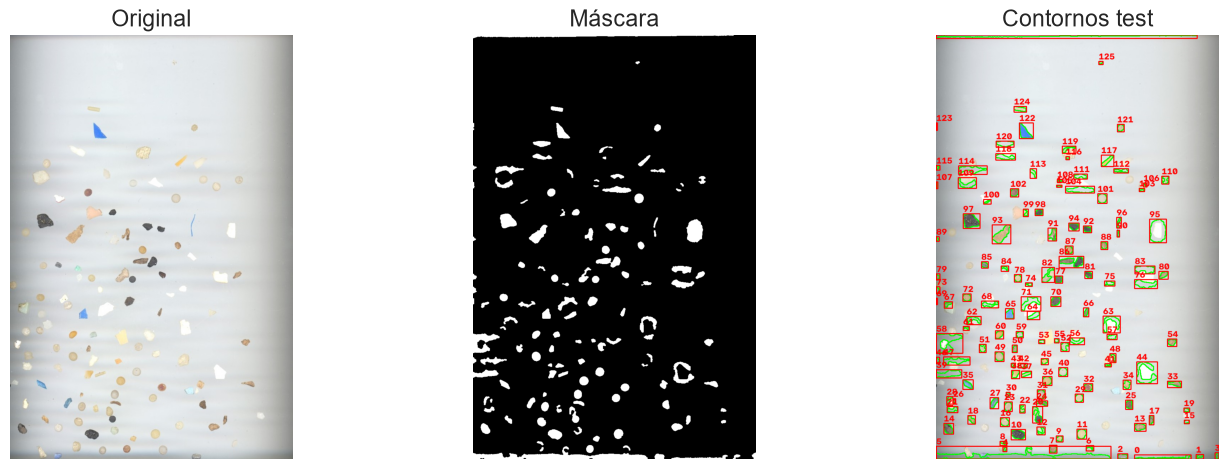

127 partículas detectadas
  label  x_min  y_min  x_max  y_max
0   TAR    503   1171    532   1186
1   TAR    204   1103    244   1133
2   TAR     16   1086     44   1118
3   TAR    524   1022    545   1048
4   TAR    408    975    433    997
label
FRA    66
PEL    38
TAR    16
Name: count, dtype: int64


In [99]:
RUTA_TEST = './MPs_test.jpg'
RUTA_CSV  = './MPs_test_bbs.csv'

# detectamos las partículas de la imagen de test
img_test = cargar(RUTA_TEST)
mask_test = segmentar(img_test)
df_test, cnts_test, bbs_test = extraer_particulas(mask_test, img_test)

# mostramos los resultamos de la detección anterior
mostrar_segmentacion(img_test, mask_test, cnts_test, bbs_test, titulo="test")

# predecimos las clases de las partículas con el modelo ya entrenado
df_test["pred"] = clasificar_todas_las_particulas(df_test) 
print(len(df_test), "partículas detectadas")

ann = pd.read_csv(RUTA_CSV)
print(ann.head())
print(ann['label'].value_counts())

# Traducción de las etiquetas del CSV a las clases del entrenamiento
MAPEO = {'TAR': 'alquitran', 'FRA': 'fragmento', 'PEL': 'pellet'}

ann_xyxy  = ann[['x_min', 'y_min', 'x_max', 'y_max']].to_numpy(dtype=float)
ann_clase = ann['label'].map(MAPEO).to_numpy()

# Si alguna etiqueta no estaba en MAPEO saldrá NaN: avisamos
assert not pd.isna(ann_clase).any(), f"Etiquetas sin mapear: {set(ann['label']) - set(MAPEO)}"

Podemos observar que si bien hay partículas que no se han detectado, existe ruido y partículas mal detectadas. Por lo que el resultado de la predicción en cualquier caso va a estar condicionado por la precisión de la segmentación de la imagen de test. Una vez obtenemos los datos debemos relacionarlos con las notaciones reales, para ello se va a realizar un emparejamiento entre las cajas detectadas y clasificadas con las cajas reales ya guardadas en MPs_test_bbs.csv y visualizaremos los resultados de la clasificación en una matriz de confusión

In [100]:
from scipy.optimize import linear_sum_assignment

def iou_matriz(a, b):
    """IoU entre cajas a (N,4) y b (M,4), ambas en formato xyxy."""
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter)

# Etiquetas reales del CSV, con las mismas siglas que devuelve el clasificador
ann_clase = ann["label"].astype(str).str.strip().str.upper().to_numpy()
desconocidas = set(ann_clase) - set(CLASES)
if desconocidas:
    raise ValueError(f"Etiquetas sin clase correspondiente en el clasificador: {desconocidas}")

det_xyxy = np.array([[x, y, x + w, y + h] for (x, y, w, h) in bbs_test], dtype=float)

# Emparejamiento uno a uno (anotación <-> detección) maximizando el IoU
IOU_MIN = 0.5
iou = iou_matriz(ann_xyxy, det_xyxy)
filas, cols = linear_sum_assignment(-iou)
pares = [(i, j) for i, j in zip(filas, cols) if iou[i, j] >= IOU_MIN]

ann_ok = {i for i, _ in pares}
det_ok = {j for _, j in pares}
sin_detectar = [i for i in range(len(ann_xyxy)) if i not in ann_ok]   # anotadas pero no detectadas
sobrantes    = [j for j in range(len(det_xyxy)) if j not in det_ok]   # detectadas pero sin anotación

y      = [ann_clase[i] for i, j in pares]
y_pred = [df_test["pred"].iloc[j] for i, j in pares]
clases = list(CLASES)

n_ann, n_det, n_match = len(ann_xyxy), len(det_xyxy), len(pares)
print(f"Anotaciones: {n_ann} | Detecciones: {n_det} | Emparejadas: {n_match}")
print(f"Anotaciones sin detectar: {len(sin_detectar)}")
print(f"Detecciones sin anotación (falsos positivos de segmentación): {len(sobrantes)}")

# Tabla de depuración: una fila por partícula emparejada, con sus características
df_pares = pd.DataFrame({
    "ann": [i for i, _ in pares],
    "det": [j for _, j in pares],
    "iou": [iou[i, j] for i, j in pares],
    "real": y,
    "pred": y_pred,
})
feat = df_test.loc[df_pares["det"], ["circularidad", "L", "a", "b"]].reset_index(drop=True)
df_pares = pd.concat([df_pares, feat], axis=1)
print(f"IoU medio de los emparejamientos: {df_pares['iou'].mean():.2f}")

Anotaciones: 120 | Detecciones: 127 | Emparejadas: 62
Anotaciones sin detectar: 58
Detecciones sin anotación (falsos positivos de segmentación): 65
IoU medio de los emparejamientos: 0.65


Vemos que en la detección de partículas en la imagen, de las 127 detecciones solo se han logrado emparejar 62, han habido 58 particulas que no se han detectado y 65 falsos positivos. Se han emparejado con éxito el 65% de las partículas detectadas. Esto es debido a que el ruido y la diferencia de tonalidades en el fondo de la imagen de test produce errores en la segmentación impiden detectar correctamente casi la mitad de las partículas de la imagen

Accuracy  = 0.758
Precision = 0.797
Recall    = 0.758
F1 Score  = 0.739

              precision    recall  f1-score   support

         FRA       0.77      0.89      0.83        27
         PEL       0.69      0.86      0.77        21
         TAR       1.00      0.36      0.53        14

    accuracy                           0.76        62
   macro avg       0.82      0.70      0.71        62
weighted avg       0.80      0.76      0.74        62



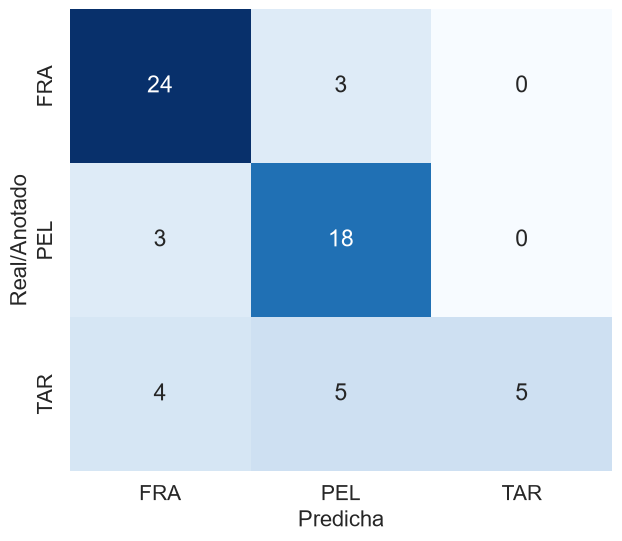

In [101]:
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)
import seaborn as sns

accuracy  = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred, average='weighted', labels=clases, zero_division=0)
recall    = recall_score(y, y_pred, average='weighted', labels=clases, zero_division=0)
f1score   = f1_score(y, y_pred, average='weighted', labels=clases, zero_division=0)

print(f"Accuracy  = {accuracy:.3f}")
print(f"Precision = {precision:.3f}")
print(f"Recall    = {recall:.3f}")
print(f"F1 Score  = {f1score:.3f}\n")
print(classification_report(y, y_pred, labels=clases, zero_division=0))

conf_matrix = confusion_matrix(y, y_pred, labels=clases)
plt.figure(figsize=(7, 6))
sns.set(font_scale=1.4)
ax = sns.heatmap(conf_matrix, annot=True, fmt='d', cbar=False, cmap='Blues',
                 xticklabels=clases, yticklabels=clases)
ax.set_xlabel("Predicha", fontsize=16)
ax.set_ylabel("Real/Anotado", fontsize=16)
plt.show()

Por otro otro lado, de las 62 partículas detectadas correctamente se han podido clasificar con éxito 47, prodicendo errores en la clasificación de partículas de Fragment (3 se han clasificado como Pellet y 4 como Alquitran) y de Pellet (3 se han clasificado como Fragment y 5 como Alquitrán). Por otro lado se han clasificado exitosamente todas las partículas de Alquitran detectadas correctamente.

Esto nos da un índice de acierto en clasificación basado en umbrales del 75%